<a href="https://colab.research.google.com/github/saichandanss2190/ITA0315-Mobile-Computing/blob/main/MC_Exp_19.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 H (dB)    Handoffs  Ping-pongs
    0.0          35          34
    2.0          27          26
    4.0          11          10
    6.0           7           6
    8.0           3           2
   10.0           1           0


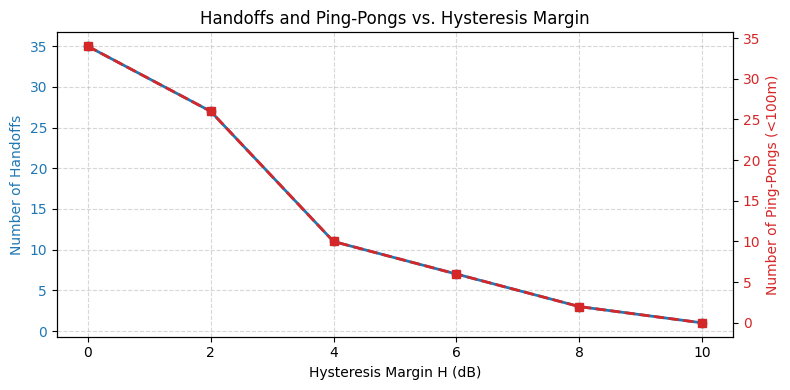

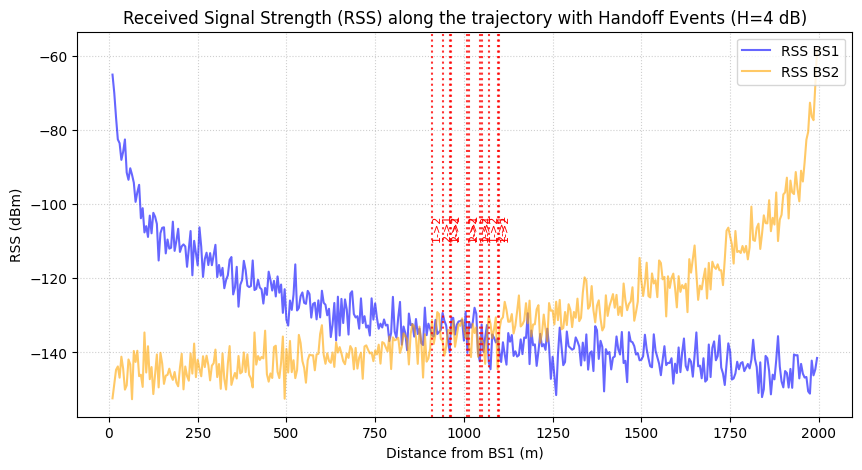

In [2]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)
D = 2000.0
P0, n, sigma = -30.0, 3.5, 4.0
x = np.arange(10, D, 5.0)  # BS1 at x=0, BS2 at x=D (metres)

# dBm at 1 m, path-loss exponent, shadowing sd (dB)
# mobile moves from BS1 to BS2
def rss(d, shadow):
    return P0 - 10 * n * np.log10(d) + shadow

r1 = rss(x, rng.normal(0, sigma, x.size))
r2 = rss(D - x, rng.normal(0, sigma, x.size))

def run(H):
    serving, handoffs, log = 1, 0, []
    for xi, a, b in zip(x, r1, r2):
        if serving == 1 and b > a + H:
            serving, handoffs = 2, handoffs + 1
            log.append((float(xi), '1->2'))
        elif serving == 2 and a > b + H:
            serving, handoffs = 1, handoffs + 1
            log.append((float(xi), '2->1'))

    # Calculate ping-pongs
    # A ping-pong can be defined as subsequent handoffs occurring within a short distance window (e.g., < 100m)
    ping_pongs = 0
    for i in range(1, len(log)):
        if log[i][0] - log[i-1][0] < 100.0:
            ping_pongs += 1

    return handoffs, ping_pongs, log

H_vals = [0, 2, 4, 6, 8, 10]
handoff_results = []
ping_pong_results = []
logs = {}

print(f"{'H (dB)':>7}{'Handoffs':>12}{'Ping-pongs':>12}")
for H in H_vals:
    h, pp, log = run(H)
    handoff_results.append(h)
    ping_pong_results.append(pp)
    logs[H] = log
    print(f"{H:7.1f}{h:12d}{pp:12d}")

# --- Graph 1: Handoffs & Ping-Pongs vs Hysteresis Margin H ---
fig, ax1 = plt.subplots(figsize=(8, 4))

color = 'tab:blue'
ax1.set_xlabel('Hysteresis Margin H (dB)')
ax1.set_ylabel('Number of Handoffs', color=color)
ax1.plot(H_vals, handoff_results, marker='o', color=color, linewidth=2, label='Handoffs')
ax1.tick_params(axis='y', labelcolor=color)
ax1.grid(True, linestyle='--', alpha=0.5)

ax2 = ax1.twinx()
color = 'tab:red'
ax2.set_ylabel('Number of Ping-Pongs (<100m)', color=color)
ax2.plot(H_vals, ping_pong_results, marker='s', color=color, linestyle='--', linewidth=2, label='Ping-Pongs')
ax2.tick_params(axis='y', labelcolor=color)

plt.title('Handoffs and Ping-Pongs vs. Hysteresis Margin')
fig.tight_layout()
plt.show()

# --- Graph 2: RSS and Handoff Events along the path (for H=4) ---
plt.figure(figsize=(10, 5))
plt.plot(x, r1, label='RSS BS1', color='blue', alpha=0.6)
plt.plot(x, r2, label='RSS BS2', color='orange', alpha=0.6)

# Plot handoffs for H=4 to demonstrate the trajectory
_, _, log_h4 = run(4)
for xi, direction in log_h4:
    plt.axvline(x=xi, color='red', linestyle=':', alpha=0.8)
    plt.text(xi, -110, f"{direction}", rotation=90, verticalalignment='bottom', fontsize=8, color='red')

plt.title('Received Signal Strength (RSS) along the trajectory with Handoff Events (H=4 dB)')
plt.xlabel('Distance from BS1 (m)')
plt.ylabel('RSS (dBm)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()